# Laboratorio 3: Construcción de un Modelo Robusto

Diagnostica un modelo con overfitting y mejora su capacidad de generalización mediante técnicas de regularización.

## Objetivos
- Analizar curvas de aprendizaje.
- Detectar overfitting.
- Implementar técnicas de regularización.
- Comparar un modelo base y uno robusto.
- Justificar técnicamente las decisiones.

**Restricción**: Solo puedes modificar técnicas relacionadas con la generalización. No está permitido cambiar el optimizador, la función de pérdida ni aumentar arbitrariamente el número de épocas.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

(x_train,y_train),(x_test,y_test)=keras.datasets.cifar10.load_data()

x_train=x_train.astype("float32")/255.
x_test=x_test.astype("float32")/255.

N_TRAIN=5000
x_train=x_train[:N_TRAIN]
y_train=y_train[:N_TRAIN]

print(x_train.shape)


c:\Users\Rocio\anaconda3\envs\DL_DuocUC_JM\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


(5000, 32, 32, 3)


## 1. Analiza el conjunto de datos

**Responde:**
1. ¿Por qué reducir el conjunto de entrenamiento favorece el overfitting?
2. ¿Por qué normalizamos los píxeles entre 0 y 1?

In [2]:
def create_baseline():
    model=keras.Sequential([
        layers.Conv2D(32,3,padding='same',activation='relu',input_shape=(32,32,3)),
        layers.MaxPooling2D(),
        layers.Conv2D(64,3,padding='same',activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(128,3,padding='same',activation='relu'),
        layers.Flatten(),
        layers.Dense(128,activation='relu'),
        layers.Dense(10,activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

baseline=create_baseline()

history_base=baseline.fit(
    x_train,y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64
)


c:\Users\Rocio\anaconda3\envs\DL_DuocUC_JM\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.2480 - loss: 2.0451 - val_accuracy: 0.3560 - val_loss: 1.8282
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.3957 - loss: 1.6783 - val_accuracy: 0.4240 - val_loss: 1.6158
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.4568 - loss: 1.5104 - val_accuracy: 0.4670 - val_loss: 1.5190
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.5188 - loss: 1.3441 - val_accuracy: 0.4790 - val_loss: 1.4912
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.5705 - loss: 1.2184 - val_accuracy: 0.4680 - val_loss: 1.4618
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.5990 - loss: 1.0940 - val_accuracy: 0.5140 - val_loss: 1.4508
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.6777 - loss: 0.9375 - val_accuracy: 0.5010 - val_loss: 1.4506
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7063 - loss: 0.8456 - val_accuracy: 0.5570 - v

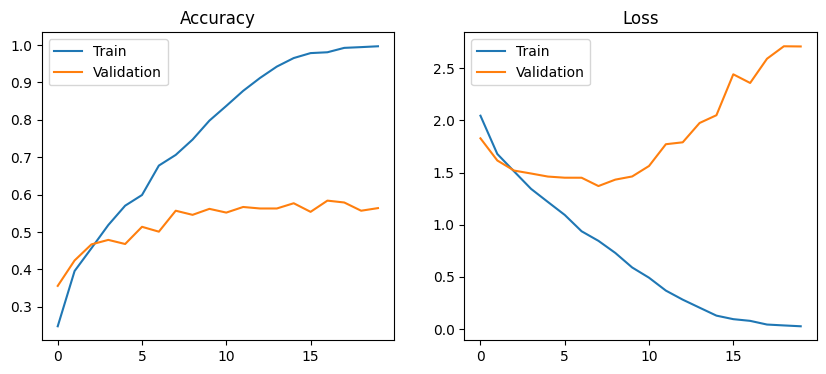

In [3]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history_base.history['accuracy'],label='Train')
plt.plot(history_base.history['val_accuracy'],label='Validation')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history_base.history['loss'],label='Train')
plt.plot(history_base.history['val_loss'],label='Validation')
plt.legend()
plt.title("Loss")

plt.show()


## 2. Diagnóstico

- ¿Existe overfitting?
- ¿Desde qué época comienza?
- ¿Qué evidencia entregan las curvas?

## 3. Diseña una estrategia

Selecciona al menos **tres** técnicas de regularización:

- Dropout
- EarlyStopping
- Data Augmentation
- Reducir complejidad del modelo
- Batch Normalization (opcional)

Justifica tus decisiones antes de programar.

In [ ]:
# Escribe aquí la justificación de tu estrategia (comentarios o Markdown).

In [ ]:
# ======================================
# IMPLEMENTA AQUÍ:
# 1. 3 tecnicas de regularización 
# 2. compila el modelo
# 4. Entrenamiento
# ======================================


## 4. Comparación

In [ ]:
# Evalúa el modelo base y el modelo robusto.
# Grafica las curvas de aprendizaje.
# Compara Accuracy y Loss.


Completa la tabla:

| Modelo | Train Acc | Val Acc | Test Acc |
|---|---:|---:|---:|
| Baseline | | | |
| Modelo Robusto | | | |


## 5. Auditoría

Genera una matriz de confusión y un classification report para el modelo robusto.

In [ ]:
# Escribe aquí el código para la auditoría del modelo.

## Registro de experimentos

| Experimento | Cambio realizado | Resultado | ¿Se conserva? |
|---|---|---|---|
| Baseline | Ninguno | | |
| Exp. 1 | | | |
| Exp. 2 | | | |
| Exp. 3 | | | |


# Conclusiones

1. ¿Qué provocó el overfitting?
2. ¿Qué técnicas implementaste?
3. ¿Cuál fue la más efectiva?
4. ¿Qué harías para seguir mejorando el modelo?
5. ¿El modelo generaliza adecuadamente? Justifica con evidencia.
